# K-Means / كي-مينز

Run the cells in order with **Shift + Enter**. The CSV has 30 made-up points, two coordinates on the same scale, and no labels. It is original to ML Visual and released under CC0 1.0.

شغّل الخلايا بالترتيب باستخدام **Shift + Enter**. يحتوي الملف على 30 نقطة اصطناعية بإحداثيَين على المقياس نفسه ومن دون تسميات. البيانات من إعداد ML Visual ومنشورة بموجب CC0 1.0.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/clustering_points.csv"
X = pd.read_csv(url)[["x", "y"]].to_numpy()
X[:5]

array([[0.5776 , 0.78424],
       [0.52881, 0.70383],
       [0.25844, 0.32205],
       [0.22855, 0.35964],
       [0.69219, 0.25466]])

## Fit the centres / احسب المراكز

Start with three centres. Try `k = 2` and rerun the rest of the notebook. The cluster IDs are just names. `inertia_` is the sum of squared distances to the nearest centres (WCSS).

ابدأ بثلاثة مراكز. جرّب مركزين وأعد تشغيل بقية الدفتر. أرقام المجموعات مجرّد أسماء. تمثّل `inertia_` مجموع مربّعات المسافات إلى أقرب المراكز.

In [2]:
from sklearn.cluster import KMeans

k = 3
settings = dict(init="k-means++", n_init=10, random_state=42)
model = KMeans(n_clusters=k, **settings).fit(X)
print(model.cluster_centers_)
print(model.inertia_)

[[0.73426  0.269142]
 [0.179072 0.305489]
 [0.528102 0.747773]]
0.09769225597999999


## See it / شاهد النتيجة

The crosses mark the centres. On the right, look for the bend where adding another centre starts to help much less. Is it at the K you chose?

علامات الزائد تحدّد المراكز. في الرسم على اليمين، ابحث عن الانحناء الذي تقلّ بعده فائدة إضافة مركز آخر. هل يقع عند العدد الذي اخترته؟

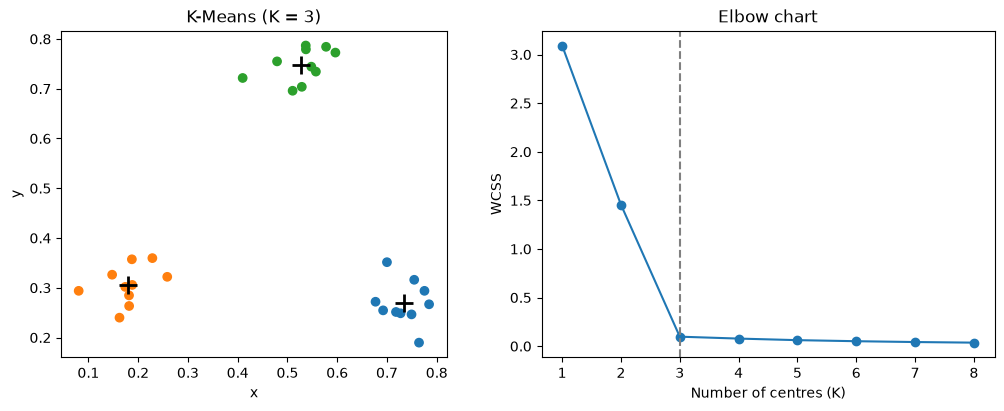

In [3]:
ks = range(1, 9)
wcss = [KMeans(n_clusters=count, **settings).fit(X).inertia_ for count in ks]
centres = model.cluster_centers_
fig, (scatter, elbow) = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
scatter.scatter(X[:, 0], X[:, 1], c=model.labels_, cmap="tab10", vmin=0, vmax=9)
scatter.scatter(centres[:, 0], centres[:, 1], marker="+", s=180, linewidths=2, color="black")
scatter.set(title=f"K-Means (K = {k})", xlabel="x", ylabel="y", aspect="equal")
elbow.plot(list(ks), wcss, "o-")
elbow.axvline(k, color="gray", linestyle="--")
elbow.set(title="Elbow chart", xlabel="Number of centres (K)", ylabel="WCSS", xticks=list(ks))
plt.show()